<a href="https://colab.research.google.com/github/avialazraki/DI_Bootcamp/blob/main/Week8_Day4_ExercisesXP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 · Day 4 — Exercises XP: Diabetes Classification
**Objective:** Explore the diabetes dataset, preprocess features, train a logistic regression classifier, and evaluate its predictions using accuracy, confusion matrix, precision, recall, F1, decision boundary, and ROC/AUC.

**Important:** This is an educational classification exercise, **not** a medical diagnostic tool. The dataset label indicates recorded diabetes status, not whether an individual will develop diabetes in the future. A random split estimates performance on held-out records, not prospective clinical performance.

## Exercise 1 — Understanding the problem and data collection
We want to predict the dataset's binary `diabetes` label from patient attributes. First, download and inspect the supplied dataset, count positive/negative examples, and split into training and test data.

**Dataset source:** [DI Diabetes prediction dataset ZIP](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%204/Day%202/Diabetes%20prediction%20dataset.zip). If Colab cannot download it, upload the ZIP or CSV to the Colab session and rerun the loading cell.

In [1]:
import io
import zipfile
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score)

RANDOM_STATE = 42
DATASET_URL = ('https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/'
               'Week%204/Day%202/Diabetes%20prediction%20dataset.zip')


In [2]:
def load_diabetes_data():
    """Read the first diabetes CSV from local files or the course ZIP."""
    local_candidates = list(Path('.').glob('*diabetes*.csv')) + list(Path('.').glob('*Diabetes*.csv'))
    for path in local_candidates:
        print('Loading local CSV:', path)
        return pd.read_csv(path)

    local_zips = list(Path('.').glob('*diabetes*.zip')) + list(Path('.').glob('*Diabetes*.zip'))
    if local_zips:
        print('Loading local ZIP:', local_zips[0])
        zf = zipfile.ZipFile(local_zips[0])
    else:
        print('Downloading course dataset...')
        try:
            with urlopen(DATASET_URL, timeout=45) as response:
                zip_bytes = response.read()
            zf = zipfile.ZipFile(io.BytesIO(zip_bytes))
        except Exception as exc:
            raise RuntimeError('Dataset download failed. Upload the supplied ZIP or CSV to Colab, then rerun.') from exc
    csv_files = [f for f in zf.namelist() if f.lower().endswith('.csv') and not f.startswith('__MACOSX/')]
    if not csv_files:
        raise ValueError('No CSV found in dataset ZIP.')
    preferred = sorted(csv_files, key=lambda s: ('diabetes' not in s.lower(), len(s)))[0]
    print('Reading:', preferred)
    with zf.open(preferred) as f:
        return pd.read_csv(f)

df = load_diabetes_data()
df.columns = df.columns.str.strip()
print('Dataset shape:', df.shape)
print('Columns and types:')
print(df.dtypes)
print('Missing values:')
print(df.isna().sum())
display(df.head())
display(df.describe(include='all').T)


Reading: diabetes_prediction_dataset.csv
Dataset shape: (100000, 9)
Columns and types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object
Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


In [3]:
target_candidates = [c for c in df.columns if c.lower().strip().replace(' ', '_') in
                     {'diabetes', 'outcome', 'diabetes_status', 'diabetic'}]
if not target_candidates:
    raise ValueError(f'Could not identify diabetes target. Available columns: {df.columns.tolist()}')
target = target_candidates[0]
print('Target column:', target)
print('Raw target distribution:')
print(df[target].value_counts(dropna=False))

# Binary labels: handle numeric 0/1 or common yes/no strings.
raw_y = df[target]
if pd.api.types.is_numeric_dtype(raw_y):
    y = pd.to_numeric(raw_y, errors='coerce')
else:
    y = raw_y.astype('string').str.strip().str.lower().map(
        {'yes': 1, 'no': 0, 'true': 1, 'false': 0, '1': 1, '0': 0,
         'positive': 1, 'negative': 0})
valid = y.notna()
X = df.loc[valid].drop(columns=[target]).copy()
y = y.loc[valid].astype(int)
if set(y.unique()) != {0, 1}:
    raise ValueError(f'Expected both binary classes 0 and 1, got {sorted(y.unique())}')

# Remove identifiers and duplicates, if present. Avoid data leakage.
identifier_cols = [c for c in X.columns if c.lower() in {'id', 'patient_id', 'person_id', 'index', 'unnamed: 0'}]
X = X.drop(columns=identifier_cols)
combined = X.copy()
combined['_target_'] = y.to_numpy()
combined = combined.drop_duplicates()
y = combined.pop('_target_').astype(int)
X = combined
print('Clean records:', len(X))
print(f'Negative (0): {(y == 0).sum():,} | Positive (1): {(y == 1).sum():,}')
print('Class proportions:', y.value_counts(normalize=True).sort_index().round(3).to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'Test:', X_test.shape)


Target column: diabetes
Raw target distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64
Clean records: 96146
Negative (0): 87,664 | Positive (1): 8,482
Class proportions: {0: 0.912, 1: 0.088}
Train: (76916, 8) Test: (19230, 8)


## Exercise 2 — Model choice and standardization
**Model:** Logistic Regression is a suitable baseline for binary classification: it is fast, interpretable, and outputs class probabilities.

**Standardization:** Yes, scale numerical predictors with `StandardScaler`. It can improve numerical optimization and makes regularization more comparable across differently scaled features. Categorical predictors are one-hot encoded. All preprocessing is **fitted only on training data** using a pipeline, preventing test-data leakage.

In [4]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()
print('Numerical features:', numeric_cols)
print('Categorical features:', categorical_cols)

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols),
])


Numerical features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical features: ['gender', 'smoking_history']


## Exercise 3 — Train the Logistic Regression model
Train on the training set only. The held-out test set is reserved for evaluation.

In [5]:
model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print('Logistic Regression trained successfully.')


Logistic Regression trained successfully.


## Exercise 4 — Evaluation metrics
Accuracy is the proportion of all correct predictions. Because diabetes-positive cases may be less common, also examine **recall** (fraction of actual positives detected), **precision** (fraction of predicted positives that are correct), and **F1** (balance of precision and recall). A confusion matrix reveals false negatives and false positives.

Accuracy     0.9596
Precision    0.8692
Recall       0.6386
F1-score     0.7362

Classification report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



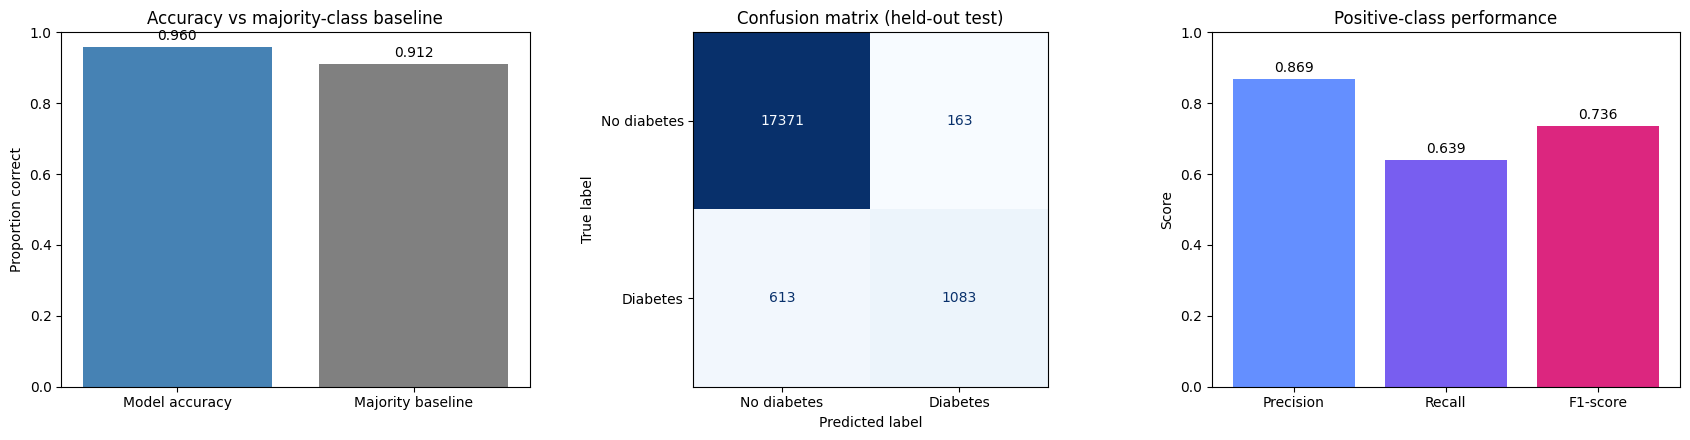

Interpretation: 1083 true positives, 17371 true negatives, 163 false positives, 613 false negatives.
False negatives are particularly important to investigate in screening-like applications.


In [6]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
metrics = pd.Series({'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1-score': f1})
print(metrics.round(4).to_string())
print('\nClassification report:\n', classification_report(y_test, y_pred, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(['Model accuracy', 'Majority baseline'],
            [accuracy, max(y_test.mean(), 1-y_test.mean())], color=['steelblue', 'gray'])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Proportion correct')
axes[0].set_title('Accuracy vs majority-class baseline')
for i, val in enumerate([accuracy, max(y_test.mean(), 1-y_test.mean())]):
    axes[0].text(i, val + 0.02, f'{val:.3f}', ha='center')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No diabetes', 'Diabetes'],
                                         ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Confusion matrix (held-out test)')
axes[2].bar(['Precision', 'Recall', 'F1-score'], [precision, recall, f1], color=['#648fff', '#785ef0', '#dc267f'])
axes[2].set_ylim(0, 1)
axes[2].set_ylabel('Score')
axes[2].set_title('Positive-class performance')
for i, val in enumerate([precision, recall, f1]):
    axes[2].text(i, val + 0.02, f'{val:.3f}', ha='center')
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'Interpretation: {tp} true positives, {tn} true negatives, {fp} false positives, {fn} false negatives.')
print('False negatives are particularly important to investigate in screening-like applications.')


## Exercise 5 — Decision boundary with accuracy
A decision boundary cannot be displayed directly in two dimensions when the main classifier uses many features. We therefore train a **separate illustrative Logistic Regression model** using two numerical features. Its decision boundary and accuracy are **not** the performance of the full-feature model.

If available, use `HbA1c_level` and `blood_glucose_level`; otherwise choose the first two numerical columns.

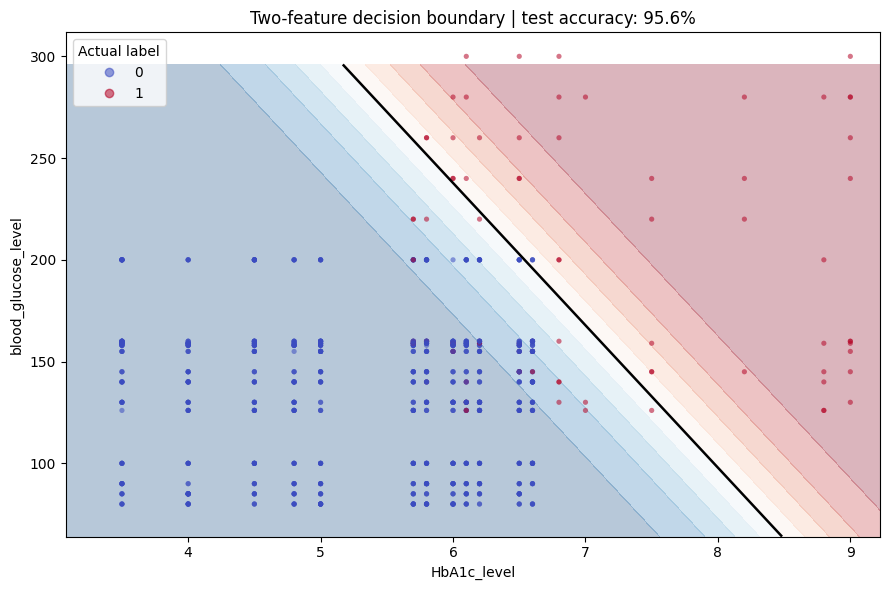

Two-feature test accuracy: 0.956; full-model test accuracy: 0.960


In [7]:
preferred = ['HbA1c_level', 'blood_glucose_level']
plot_features = preferred if all(c in numeric_cols for c in preferred) else numeric_cols[:2]
if len(plot_features) < 2:
    print('Decision boundary unavailable: fewer than two numeric features.')
else:
    boundary_model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)),
    ])
    boundary_model.fit(X_train[plot_features], y_train)
    boundary_accuracy = accuracy_score(y_test, boundary_model.predict(X_test[plot_features]))

    xvals = pd.to_numeric(X_train[plot_features[0]], errors='coerce')
    yvals = pd.to_numeric(X_train[plot_features[1]], errors='coerce')
    x_min, x_max = xvals.quantile([0.01, 0.99]).values
    y_min, y_max = yvals.quantile([0.01, 0.99]).values
    x_pad, y_pad = max((x_max-x_min)*0.08, 0.1), max((y_max-y_min)*0.08, 0.1)
    xx, yy = np.meshgrid(np.linspace(x_min-x_pad, x_max+x_pad, 180),
                         np.linspace(y_min-y_pad, y_max+y_pad, 180))
    grid = pd.DataFrame({plot_features[0]: xx.ravel(), plot_features[1]: yy.ravel()})
    zz = boundary_model.predict_proba(grid)[:, 1].reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.30)
    ax.contour(xx, yy, zz, levels=[0.5], colors='black', linewidths=1.8)
    # Sample test points for readability.
    sample_idx = X_test.sample(n=min(900, len(X_test)), random_state=RANDOM_STATE).index
    scatter = ax.scatter(X_test.loc[sample_idx, plot_features[0]],
                         X_test.loc[sample_idx, plot_features[1]],
                         c=y_test.loc[sample_idx], cmap='coolwarm', s=14, alpha=0.55,
                         edgecolors='none')
    ax.set(xlabel=plot_features[0], ylabel=plot_features[1],
           title=f'Two-feature decision boundary | test accuracy: {boundary_accuracy:.1%}')
    ax.legend(*scatter.legend_elements(), title='Actual label', loc='best')
    plt.tight_layout()
    plt.show()
    print(f'Two-feature test accuracy: {boundary_accuracy:.3f}; full-model test accuracy: {accuracy:.3f}')


## Exercise 6 — ROC curve
The ROC curve shows the true-positive rate against the false-positive rate across different decision thresholds. **AUC** summarizes ranking ability: 0.5 is chance-level and 1.0 is perfect separation. ROC/AUC should be considered alongside recall, precision and class prevalence.

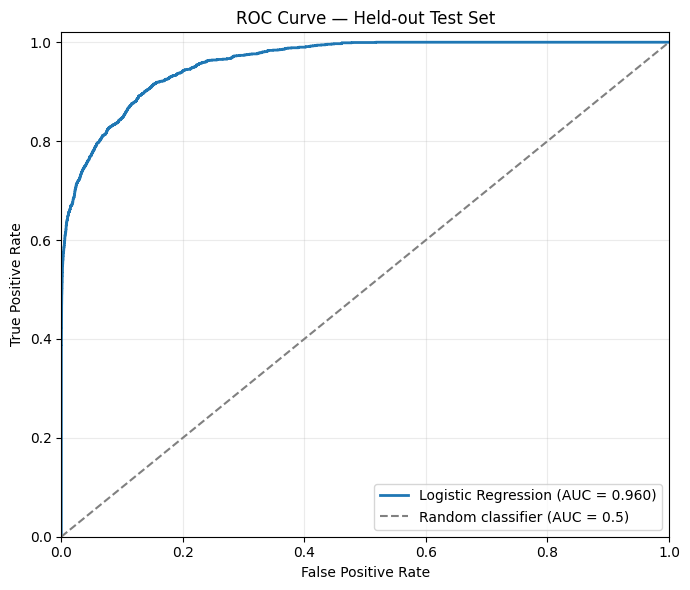

ROC AUC: 0.9599


In [8]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})', linewidth=2)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random classifier (AUC = 0.5)')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ROC Curve — Held-out Test Set', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f'ROC AUC: {auc:.4f}')


## Final conclusions and reflection
The cell below prints a results-based summary rather than inventing performance numbers before the data is run.

**Limitations:** The dataset may not represent all populations, data collection may introduce bias, and random train/test splitting does not establish clinical generalization. Accuracy can hide weak detection of the positive class. In real healthcare applications, clinical validation, fairness evaluation, calibration, and careful threshold selection are essential. No model here should be used for individual medical decisions.

**Reflection:** Using a pipeline prevents data leakage during scaling and encoding. Class imbalance makes precision and recall more informative than accuracy alone. A two-feature decision boundary is a teaching visualization, not a faithful projection of the full model.

In [9]:
print('FINAL SUMMARY')
print('-' * 60)
print(f'Dataset: {len(X):,} records; positive diabetes cases: {(y == 1).sum():,}; '
      f'negative cases: {(y == 0).sum():,}.')
print(f'Logistic Regression test accuracy: {accuracy:.3f} (majority baseline: '
      f'{max(y_test.mean(), 1-y_test.mean()):.3f}).')
print(f'Positive-class precision: {precision:.3f}, recall: {recall:.3f}, F1: {f1:.3f}.')
print(f'ROC AUC: {auc:.3f}.')
print(f'Confusion matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}.')
print('Interpretation: Compare recall and false negatives with accuracy; '
      'do not treat this exercise model as a clinical screening tool.')


FINAL SUMMARY
------------------------------------------------------------
Dataset: 96,146 records; positive diabetes cases: 8,482; negative cases: 87,664.
Logistic Regression test accuracy: 0.960 (majority baseline: 0.912).
Positive-class precision: 0.869, recall: 0.639, F1: 0.736.
ROC AUC: 0.960.
Confusion matrix: TN=17371, FP=163, FN=613, TP=1083.
Interpretation: Compare recall and false negatives with accuracy; do not treat this exercise model as a clinical screening tool.
